In [36]:
import pandas as pd
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt


In [19]:
df_03 = pd.DataFrame(pd.read_csv("D:/My_projects/Capstone_project/data/raw/03_aum_by_fund_house.csv"))
df_03

,date,fund_house,aum_lakh_crore,aum_crore,num_schemes
0,2022-03-31,SBI Mutual Fund,6.05,605000,186
1,2022-03-31,ICICI Prudential MF,4.65,465000,216
2,2022-03-31,HDFC Mutual Fund,4.35,435000,195
3,2022-03-31,Nippon India MF,2.70,270000,177
4,2022-03-31,Kotak Mahindra MF,2.70,270000,168
...,...,...,...,...,...
85,2025-12-31,Aditya Birla Sun Life MF,4.60,460000,199
86,2025-12-31,Axis Mutual Fund,3.50,350000,95
87,2025-12-31,UTI Mutual Fund,4.10,410000,142
88,2025-12-31,Mirae Asset MF,2.90,290000,56


In [20]:
df_03.head()

,date,fund_house,aum_lakh_crore,aum_crore,num_schemes
0,2022-03-31,SBI Mutual Fund,6.05,605000,186
1,2022-03-31,ICICI Prudential MF,4.65,465000,216
2,2022-03-31,HDFC Mutual Fund,4.35,435000,195
3,2022-03-31,Nippon India MF,2.70,270000,177
4,2022-03-31,Kotak Mahindra MF,2.70,270000,168


In [21]:
df_03.tail()

,date,fund_house,aum_lakh_crore,aum_crore,num_schemes
85,2025-12-31,Aditya Birla Sun Life MF,4.6,460000,199
86,2025-12-31,Axis Mutual Fund,3.5,350000,95
87,2025-12-31,UTI Mutual Fund,4.1,410000,142
88,2025-12-31,Mirae Asset MF,2.9,290000,56
89,2025-12-31,DSP Mutual Fund,2.3,230000,88


In [22]:
df_03.shape

(90, 5)

In [23]:
df_03.columns

Index(['date', 'fund_house', 'aum_lakh_crore', 'aum_crore', 'num_schemes'], dtype='str')

In [24]:
df_03.dtypes

date                  str
fund_house            str
aum_lakh_crore    float64
aum_crore           int64
num_schemes         int64
dtype: object

In [25]:
df_03.info()

<class 'pandas.DataFrame'>
RangeIndex: 90 entries, 0 to 89
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   date            90 non-null     str    
 1   fund_house      90 non-null     str    
 2   aum_lakh_crore  90 non-null     float64
 3   aum_crore       90 non-null     int64  
 4   num_schemes     90 non-null     int64  
dtypes: float64(1), int64(2), str(2)
memory usage: 3.6 KB


In [26]:
df_03.describe(include="all")

,date,fund_house,aum_lakh_crore,aum_crore,num_schemes
count,90,90,90.000000,9.000000e+01,90.000000
unique,9,10,NaN,NaN,NaN
top,2022-03-31,SBI Mutual Fund,NaN,NaN,NaN
freq,10,9,NaN,NaN,NaN
mean,NaN,NaN,4.352889,4.352889e+05,152.200000
std,NaN,NaN,2.734328,2.734328e+05,52.108832
min,NaN,NaN,1.050000,1.050000e+05,56.000000
25%,NaN,NaN,2.525000,2.525000e+05,95.000000
50%,NaN,NaN,3.450000,3.450000e+05,172.500000
75%,NaN,NaN,5.675000,5.675000e+05,195.000000


In [27]:
df_03.isna().sum()

date              0
fund_house        0
aum_lakh_crore    0
aum_crore         0
num_schemes       0
dtype: int64

In [28]:
df_03.duplicated().sum()

np.int64(0)

In [29]:
processed_path = Path("../data/processed")
processed_path.mkdir(parents=True, exist_ok=True)

df_03.to_csv(
    processed_path / "aum_by_fund_house.csv",
    index=False
)

In [30]:
processed_path = Path("../data/processed")
processed_path.mkdir(parents=True, exist_ok=True)

df_03.to_csv(
    processed_path / "fund_master.csv",
    index=False
)

In [32]:
df = pd.read_csv("D:/My_projects/Capstone_project/data/processed/aum_by_fund_house.csv")


In [33]:
df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year

In [34]:
df = df[df['year'].between(2022, 2025)]

print(df.head())
print("Years:", sorted(df['year'].unique()))
print("Fund houses:", df['fund_house'].nunique())

        date           fund_house  aum_lakh_crore  aum_crore  num_schemes  \
0 2022-03-31      SBI Mutual Fund            6.05     605000          186   
1 2022-03-31  ICICI Prudential MF            4.65     465000          216   
2 2022-03-31     HDFC Mutual Fund            4.35     435000          195   
3 2022-03-31      Nippon India MF            2.70     270000          177   
4 2022-03-31    Kotak Mahindra MF            2.70     270000          168   

   year  
0  2022  
1  2022  
2  2022  
3  2022  
4  2022  
Years: [np.int32(2022), np.int32(2023), np.int32(2024), np.int32(2025)]
Fund houses: 10


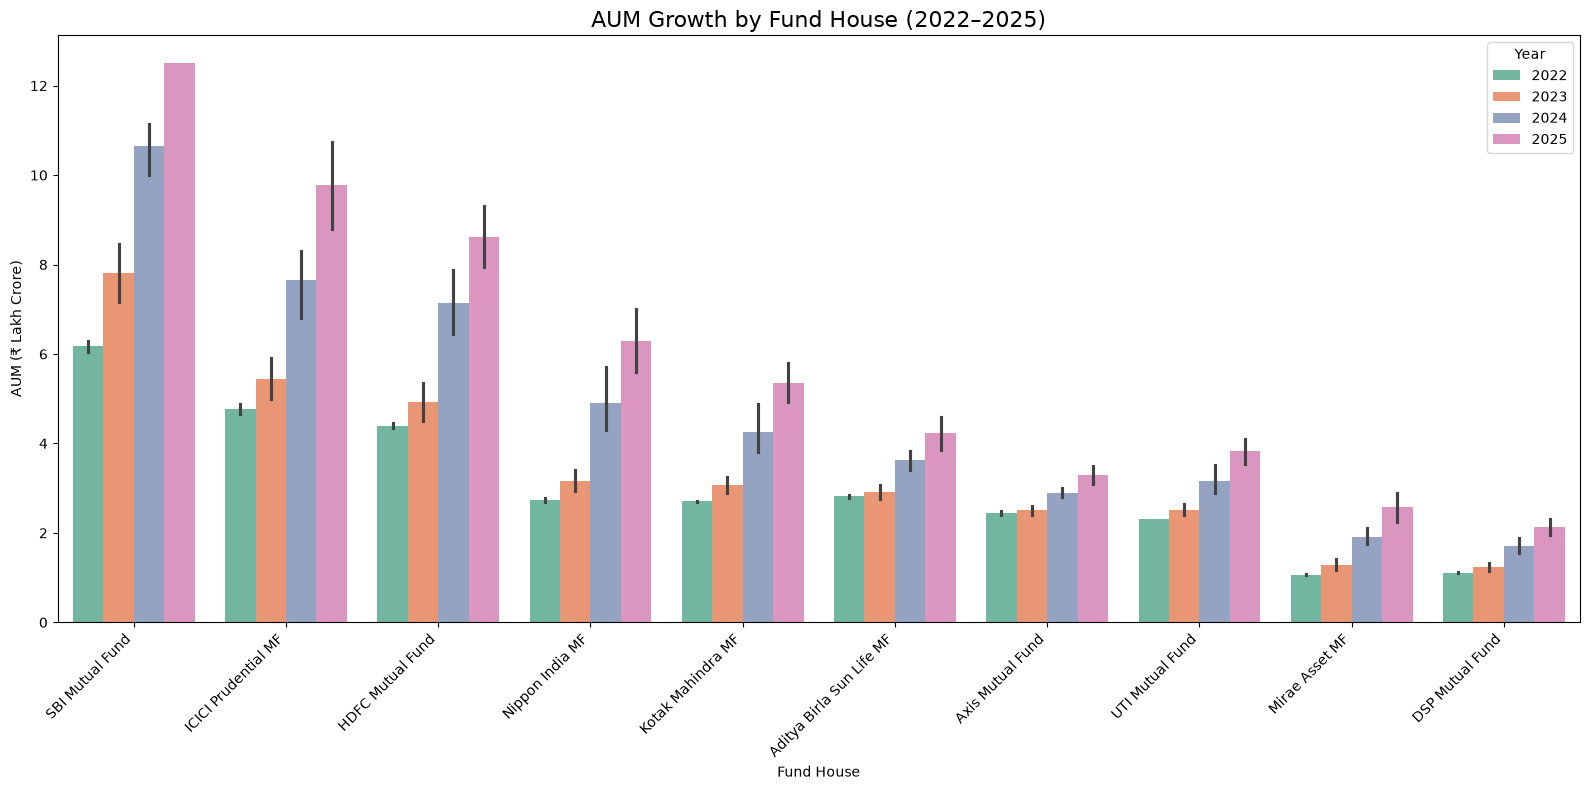

In [37]:
plt.figure(figsize=(16, 8))

sns.barplot(
    data=df,
    x='fund_house',
    y='aum_lakh_crore',
    hue='year',
    palette='Set2'
)

plt.title('AUM Growth by Fund House (2022–2025)', fontsize=16)
plt.xlabel('Fund House')
plt.ylabel('AUM (₹ Lakh Crore)')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Year')
plt.tight_layout()

plt.show()

In [38]:
print(
    df[
        (df['fund_house'] == 'SBI Mutual Fund') &
        (df['year'] == 2025)
    ][['date', 'aum_lakh_crore']]
)

         date  aum_lakh_crore
70 2025-03-31            12.5
80 2025-12-31            12.5


In [39]:
plt.savefig(
    "../reports/plots/aum_growth_by_fund_house.png",
    dpi=300,
    bbox_inches='tight'
)

<Figure size 640x480 with 0 Axes>